# Thí nghiệm 04 — Trực quan hóa kết quả Electricity

## 1. Mục tiêu và nguồn kết quả

### 1.1. Mục tiêu

Notebook trình bày kết quả dự báo chuỗi thời gian Electricity của bốn kiến trúc:

- LSTM.
- DeepKoopFormer-PatchTST.
- DeepKoopFormer-Autoformer.
- DeepKoopFormer-Informer.

Các hình được xây dựng tương ứng với Figures 15, 16 và 17 trong phần Electricity Generation Forecasting của bài báo DeepKoopFormer.

### 1.2. Nguồn dữ liệu

Kết quả được đọc từ:

`results/electricity_grid_search_e4000/`

Nguồn gồm:

- `metrics.csv`: MSE và MAE trên Train/Test.
- Các checkpoint `.pt`: dự báo và nhãn thực tế của từng cấu hình.

### 1.3. Các hình được trình bày

| Figure | Nội dung |
|---|---|
| Fig. 15 | Grid Search MSE và MAE trên tập Train |
| Fig. 16 | Grid Search MSE và MAE trên tập Test |
| Fig. 17 | So sánh dự báo sáu nguồn phát điện |

Các hình được lưu trong thư mục `figures/` để sử dụng trong báo cáo.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Locate experiment directory
EXPERIMENT_DIR = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "03_electricity_training.ipynb").is_file()
    ),
    None
)

if EXPERIMENT_DIR is None:
    raise FileNotFoundError(
        "Cannot locate Electricity experiment."
    )

RESULTS_DIR = (
    EXPERIMENT_DIR
    / "results"
    / "electricity_grid_search_e4000"
)

FIGURES_DIR = EXPERIMENT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RESULTS_DIR / "metrics.csv"

if not METRICS_PATH.is_file():
    raise FileNotFoundError(METRICS_PATH)

metrics = pd.read_csv(METRICS_PATH)

MODELS = ["LSTM", "PatchTST", "Autoformer", "Informer"]
PATCH_LENGTHS = [70, 80, 90, 100, 110, 120, 130]
HORIZONS = [2, 4, 6, 8, 10, 12, 14, 16]

required_columns = {
    "Model", "PatchLen", "Horizon",
    "Set", "MSE", "MAE"
}

assert required_columns.issubset(metrics.columns)

# Every model/configuration/split should be unique
assert not metrics.duplicated(
    ["Model", "PatchLen", "Horizon", "Set"]
).any()

print("Metric rows:", len(metrics))
print("Results:", RESULTS_DIR)
print("Figures:", FIGURES_DIR)


Metric rows: 448
Results: c:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\results\electricity_grid_search_e4000
Figures: c:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\figures



## 2. Figure 15 — Grid Search trên tập huấn luyện

### 2.1. Mục tiêu

Hình 15 khảo sát hiệu năng huấn luyện của bốn mô hình trên toàn bộ không gian Patch Length và Forecast Horizon.

### 2.2. Phương pháp

Mỗi mô hình được đánh giá trên 56 cấu hình:

$$
7\times8=56
$$

Kết quả trình bày thành hai heatmap:

- MSE trên tập Train.
- MAE trên tập Train.

Trục ngang biểu diễn Forecast Horizon, trục dọc biểu diễn Patch Length.

Các hàng lần lượt tương ứng với LSTM, PatchTST, Autoformer và Informer.

### 2.3. Ý nghĩa

Heatmap cho phép đánh giá mức độ nhạy của sai số huấn luyện đối với độ dài chuỗi đầu vào và chân trời dự báo.

Các giá trị thấp hơn tương ứng với sai số nhỏ hơn trên tập Train.

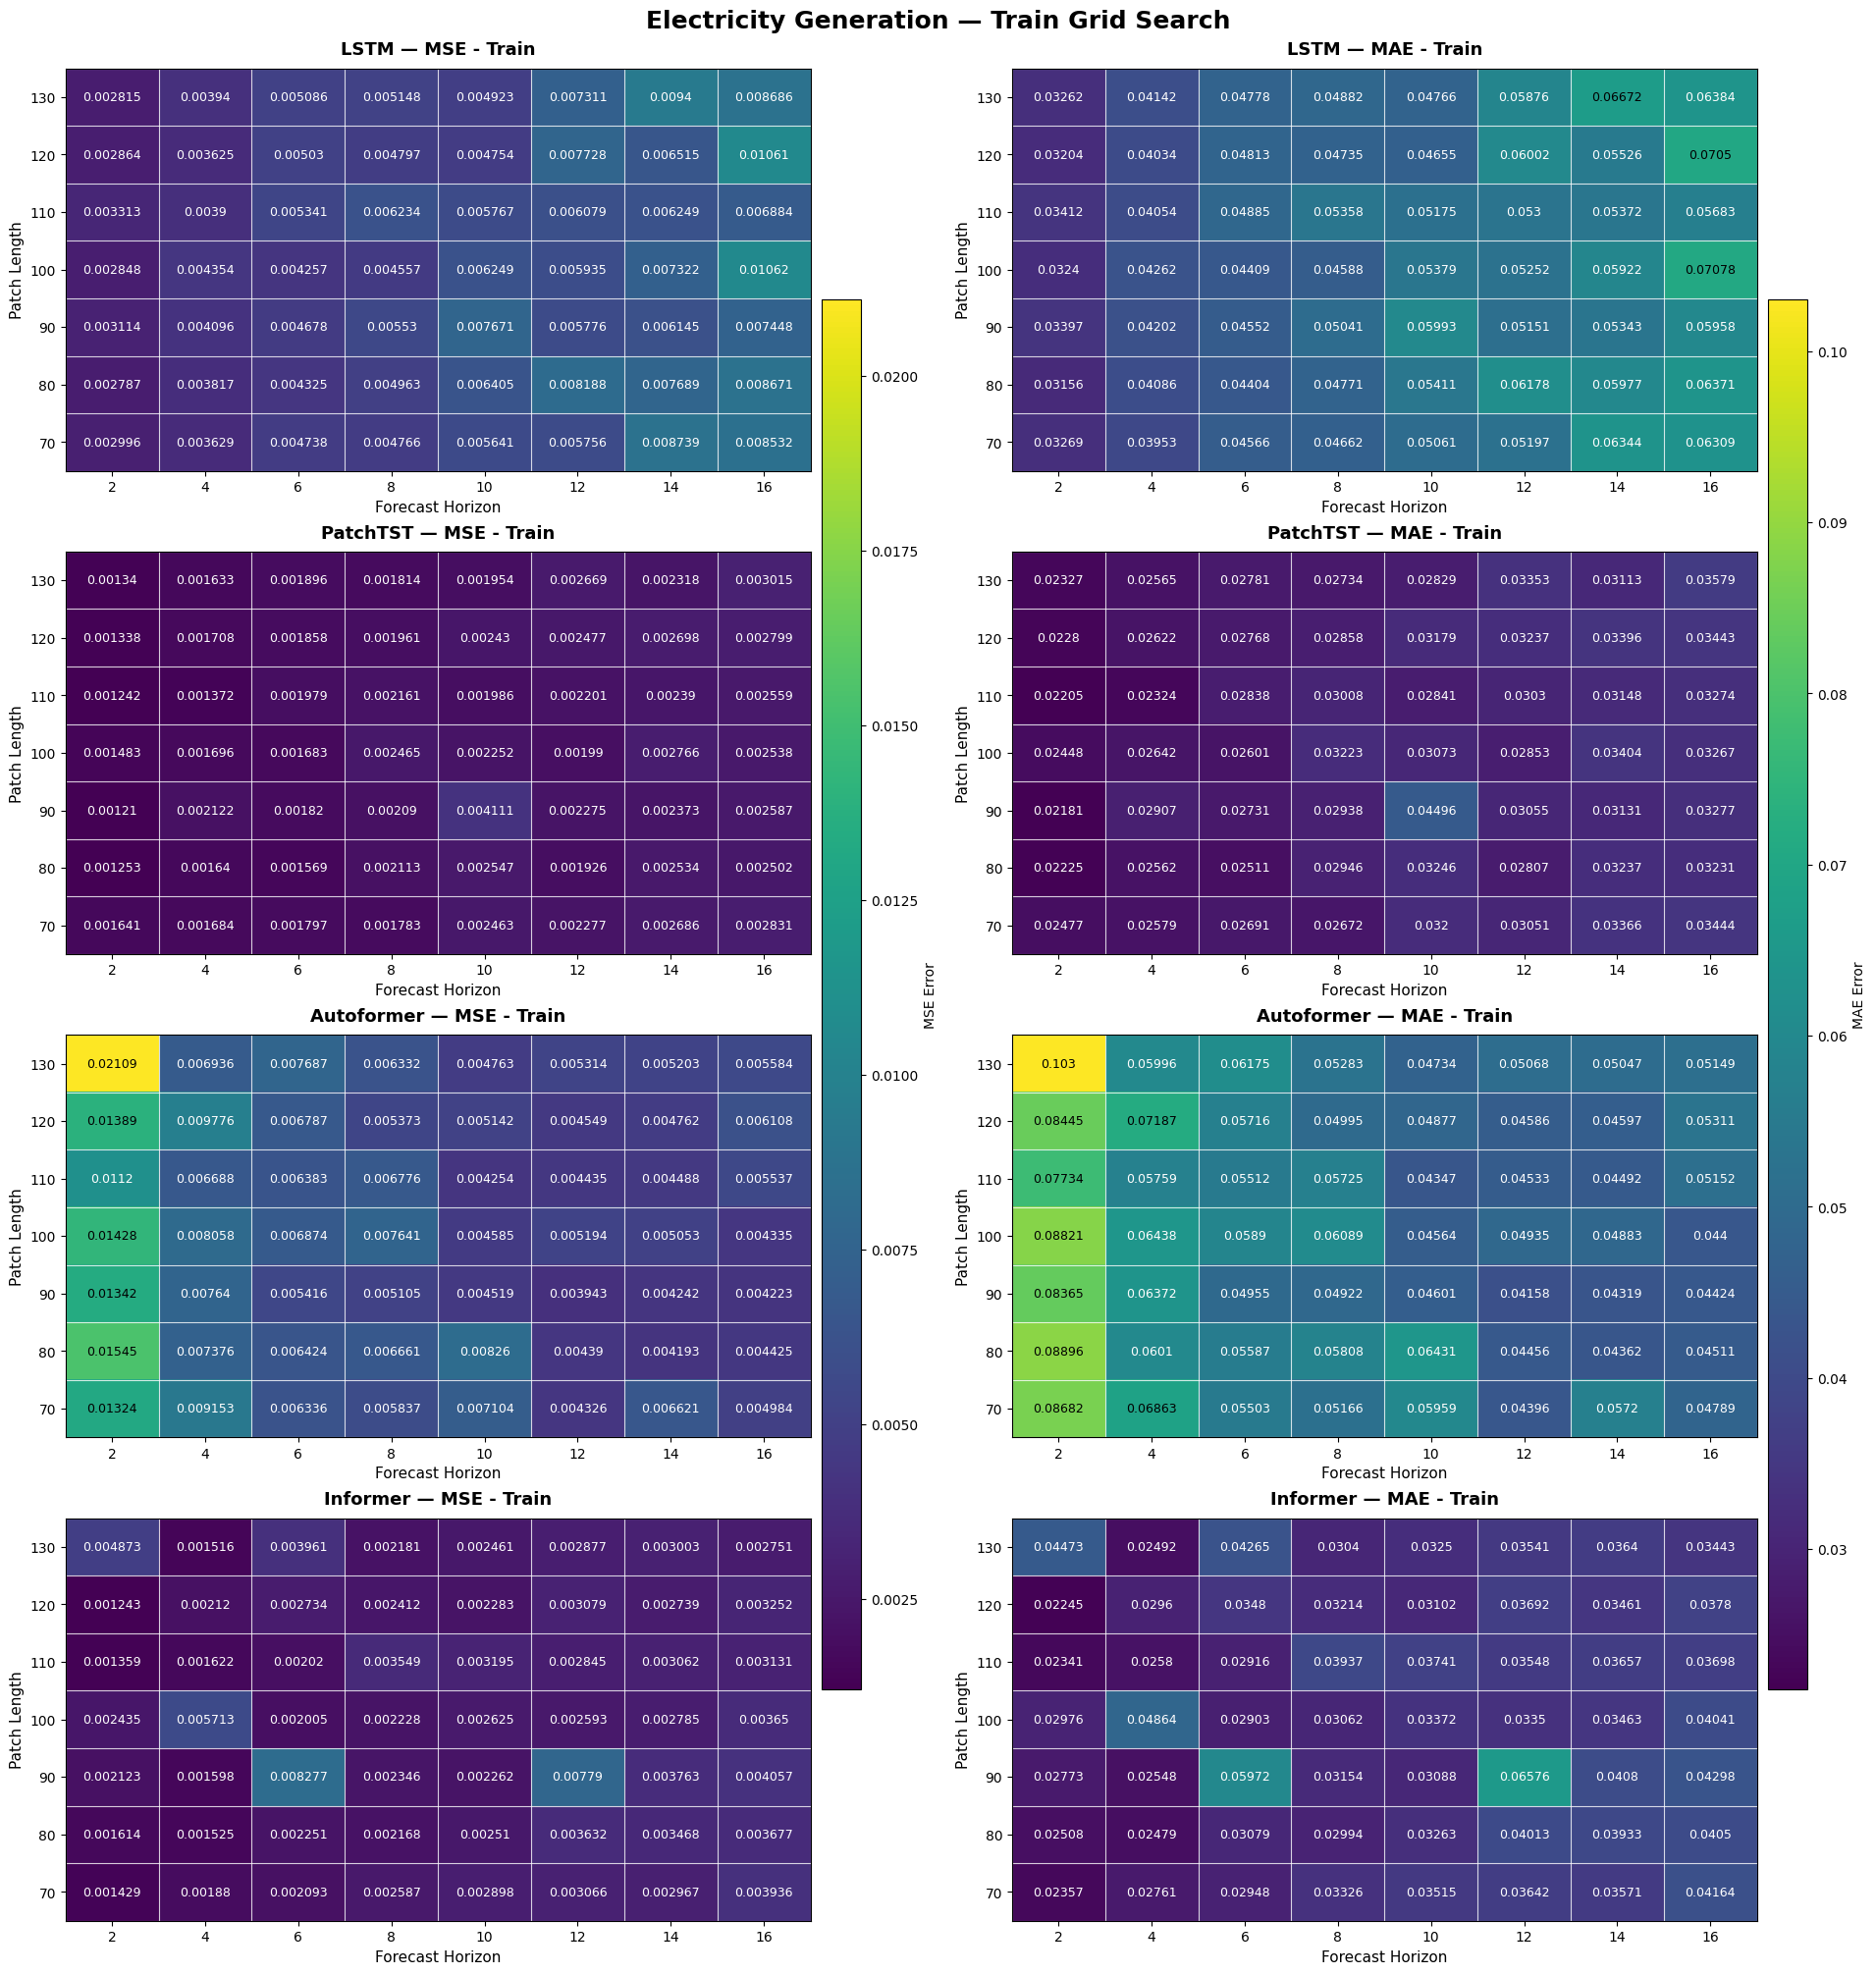

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\figures\figure_15.png


In [10]:

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


def plot_grid_search(split, filename):
    """
    Plot a 4 x 2 grid:
      Rows: LSTM, PatchTST, Autoformer, Informer
      Columns: MSE, MAE

    Every heatmap cell displays its recorded metric.
    Color scales are shared across models for each metric.
    """
    model_order = [
        "LSTM", "PatchTST", "Autoformer", "Informer"
    ]
    metric_order = ["MSE", "MAE"]

    subset = metrics.loc[
        metrics["Set"] == split
    ].copy()

    if len(subset) != 224:
        raise ValueError(
            f"{split}: expected 224 rows, got {len(subset)}"
        )

    # 1. Prepare complete metric matrices
    matrices = {}

    for model in model_order:
        model_df = subset.loc[
            subset["Model"] == model
        ]

        for metric in metric_order:
            matrix = model_df.pivot(
                index="PatchLen",
                columns="Horizon",
                values=metric
            ).reindex(
                index=PATCH_LENGTHS,
                columns=HORIZONS
            )

            values = matrix.to_numpy(dtype=float)

            if values.shape != (7, 8):
                raise ValueError(
                    f"Invalid matrix shape: {model}, {metric}"
                )

            if not np.isfinite(values).all():
                raise ValueError(
                    f"Missing or invalid values: {model}, {metric}"
                )

            matrices[(model, metric)] = values

    # 2. Shared scale per metric
    norms = {}

    for metric in metric_order:
        combined = np.concatenate([
            matrices[(model, metric)].ravel()
            for model in model_order
        ])

        vmin = float(combined.min())
        vmax = float(combined.max())

        if vmin == vmax:
            vmax = vmin + 1e-12

        norms[metric] = Normalize(
            vmin=vmin, vmax=vmax
        )

    # 3. Figure layout
    cmap = plt.get_cmap("viridis")

    fig, axes = plt.subplots(
        4, 2,
        figsize=(19, 20),
        constrained_layout=True
    )

    for row, model in enumerate(model_order):
        for col, metric in enumerate(metric_order):

            ax = axes[row, col]
            values = matrices[(model, metric)]
            norm = norms[metric]

            ax.imshow(
                values,
                cmap=cmap,
                norm=norm,
                origin="lower",
                aspect="auto",
                interpolation="nearest"
            )

            # 4. Annotate every cell with its metric
            for i in range(values.shape[0]):
                for j in range(values.shape[1]):
                    value = values[i, j]

                    r, g, b, _ = cmap(norm(value))

                    luminance = (
                        0.2126 * r
                        + 0.7152 * g
                        + 0.0722 * b
                    )

                    text_color = (
                        "black" if luminance > 0.5
                        else "white"
                    )

                    ax.text(
                        j, i,
                        f"{value:.4g}",
                        ha="center",
                        va="center",
                        fontsize=9,
                        fontweight="medium",
                        color=text_color
                    )

            # 5. Labels and titles
            ax.set_title(
                f"{model} — {metric} - {split}",
                fontsize=13,
                fontweight="bold",
                pad=10
            )

            ax.set_xlabel(
                "Forecast Horizon",
                fontsize=11
            )

            ax.set_ylabel(
                "Patch Length",
                fontsize=11
            )

            ax.set_xticks(np.arange(len(HORIZONS)))
            ax.set_xticklabels(HORIZONS)

            ax.set_yticks(np.arange(len(PATCH_LENGTHS)))
            ax.set_yticklabels(PATCH_LENGTHS)

            # 6. Draw boundaries between heatmap cells
            ax.set_xticks(
                np.arange(-0.5, len(HORIZONS), 1),
                minor=True
            )

            ax.set_yticks(
                np.arange(-0.5, len(PATCH_LENGTHS), 1),
                minor=True
            )

            ax.grid(
                which="minor",
                color="white",
                linestyle="-",
                linewidth=0.8,
                alpha=0.8
            )

            ax.tick_params(
                which="minor",
                bottom=False,
                left=False
            )

    # 7. One color scale for all models per metric
    for col, metric in enumerate(metric_order):
        mappable = ScalarMappable(
            norm=norms[metric],
            cmap=cmap
        )

        fig.colorbar(
            mappable,
            ax=axes[:, col].tolist(),
            shrink=0.75,
            pad=0.015,
            aspect=35,
            label=f"{metric} Error"
        )

    fig.suptitle(
        f"Electricity Generation — {split} Grid Search",
        fontsize=18,
        fontweight="bold"
    )

    # 8. Save
    output_path = FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


# Figure 15 — Training Set
plot_grid_search(
    split="Train",
    filename="figure_15.png"
)


## 3. Figure 16 — Grid Search trên tập kiểm tra

### 3.1. Mục tiêu

Hình 16 trình bày hiệu năng dự báo của bốn mô hình trên tập Test, sử dụng cùng không gian cấu hình như Hình 15.

### 3.2. Phương pháp

Kết quả được biểu diễn bằng tám heatmap, gồm:

- Bốn heatmap Test MSE.
- Bốn heatmap Test MAE.

Các giá trị được trích xuất từ bảng metric của từng cấu hình.

### 3.3. Ý nghĩa

Việc so sánh Hình 15 và Hình 16 cho phép phân biệt khả năng khớp dữ liệu huấn luyện với chất lượng dự báo trên dữ liệu kiểm tra.

Sự chênh lệch giữa Train và Test phản ánh mức độ khác biệt về sai số trên hai tập dữ liệu.


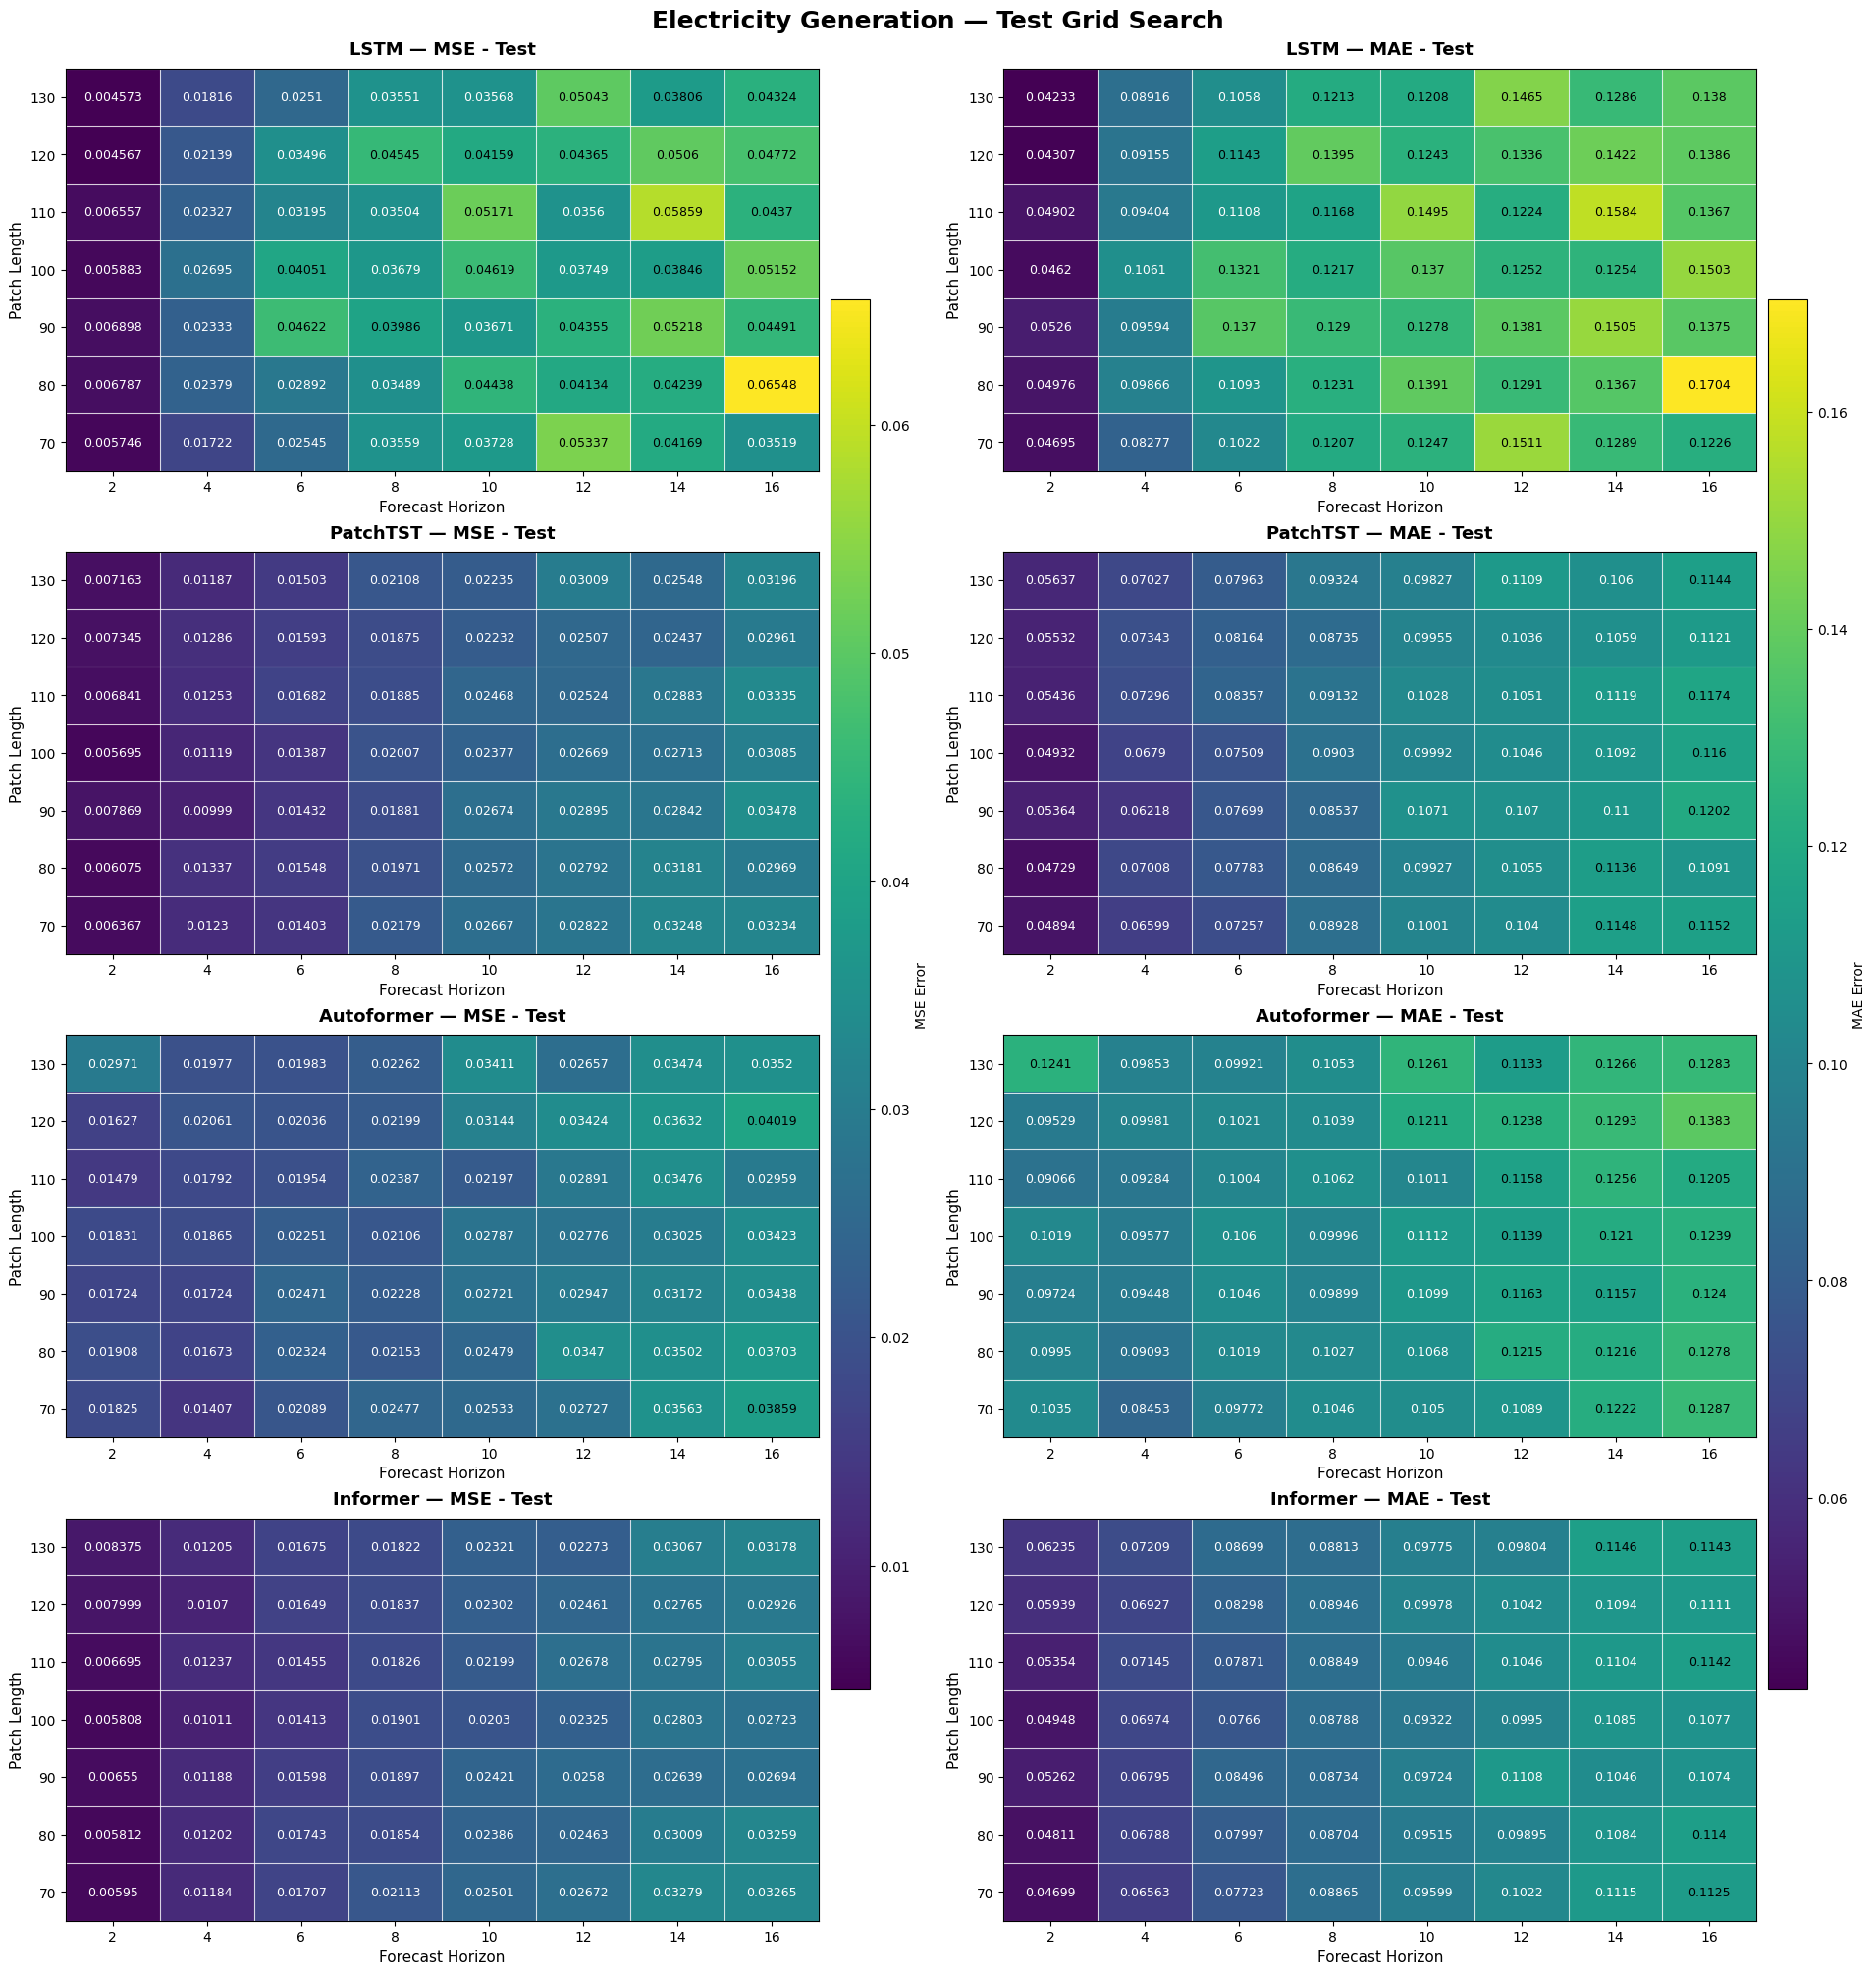

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\figures\figure_16.png


In [11]:

# Figure 16 — Test Set

plot_grid_search(
    split="Test",
    filename="figure_16.png"
)



## 4. Figure 17 — So sánh kết quả dự báo Electricity

### 4.1. Mục tiêu

Hình 17 so sánh dự báo của bốn mô hình với Ground Truth trên sáu nguồn phát điện.

Các nguồn phát điện gồm:

1. Biomass.
2. Fossil Brown Coal/Lignite.
3. Fossil Gas.
4. Fossil Hard Coal.
5. Fossil Oil.
6. Geothermal Energy.

### 4.2. Cấu hình

| Tham số | Giá trị |
|---|---|
| Patch Length | 70 |
| Forecast Horizon | 8 |
| Model dimension | 96 |
| Số kênh | 6 |

Các dự báo được lấy từ checkpoint của những mô hình đã huấn luyện trên cùng cấu hình.

### 4.3. Phương pháp biểu diễn

Mỗi subplot tương ứng một nguồn phát điện.

Giá trị thực tế và dự báo được so sánh trên cùng cửa sổ thời gian, bảo đảm các mô hình sử dụng cùng target.

Các giá trị được biểu diễn trên thang chuẩn hóa của dữ liệu thực nghiệm.

### 4.4. Ý nghĩa

Hình cho phép quan sát mức độ bám sát Ground Truth, sai lệch biên độ và khả năng phản ánh các biến động trong từng nguồn phát điện.

Việc so sánh được thực hiện trên cùng tập Test và cùng cấu hình dự báo.

LSTM checkpoint hidden size: 48


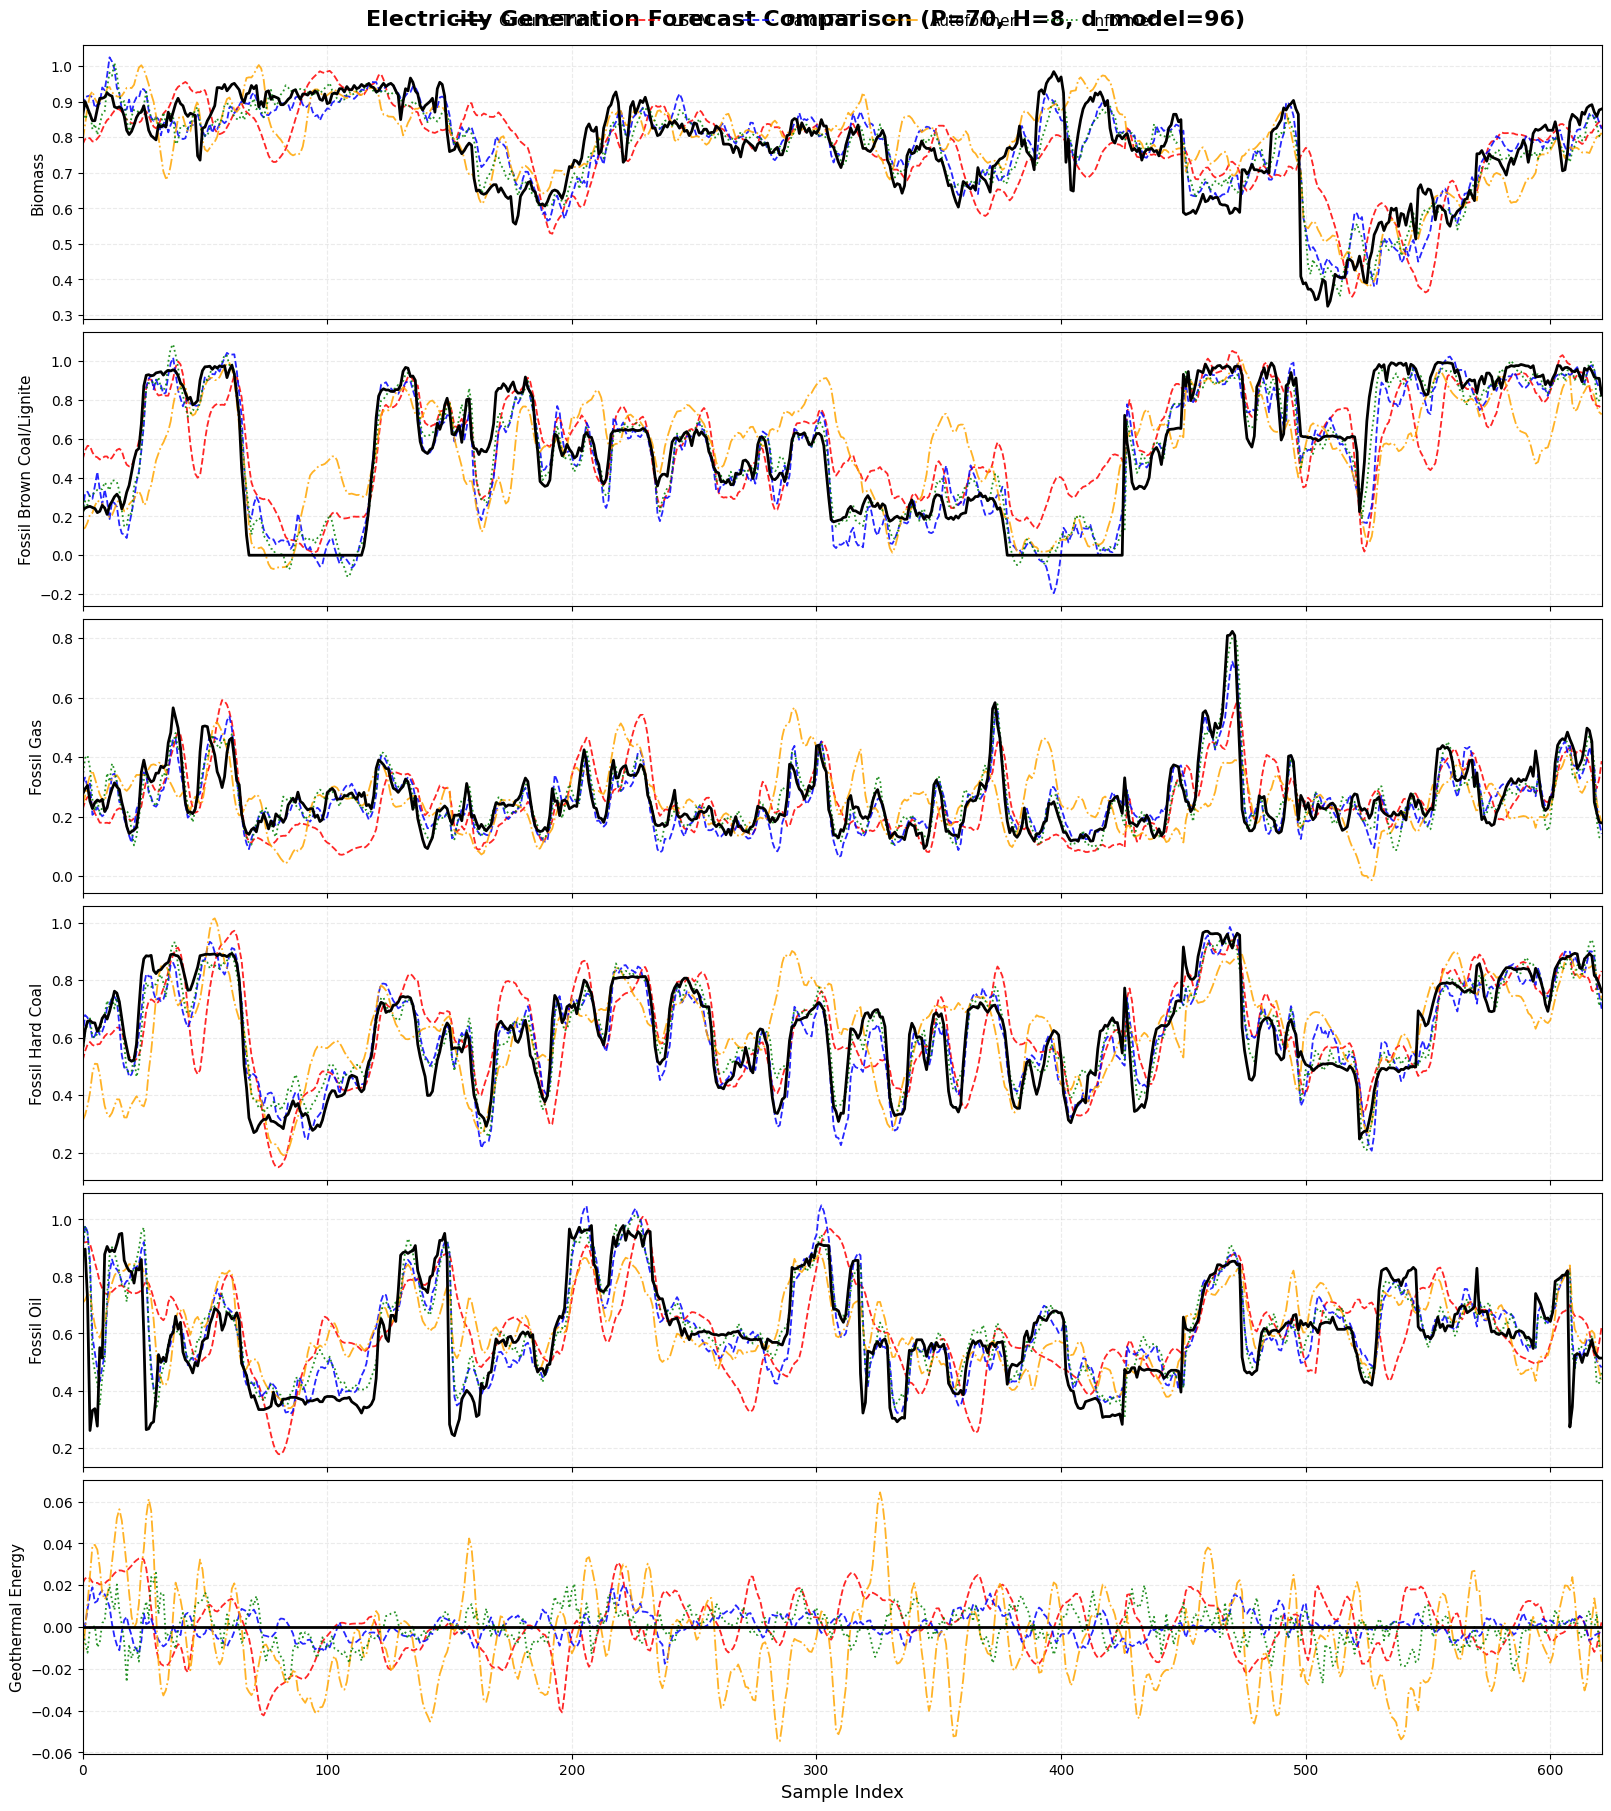

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\04_electricity\figures\figure_17.png
Test samples: 622
Channels: 6
Dataset hash: c024e2bb9460bf6e35d6f3353b82b6d90bee422366be0d6b3bb769a340eb0f0f


In [ ]:
P = 70
H = 8
D_MODEL = 96
N_CHANNELS = 6

model_order = [
    "LSTM", "PatchTST", "Autoformer", "Informer"
]

channel_names = [
    "Biomass",
    "Fossil Brown Coal/Lignite",
    "Fossil Gas",
    "Fossil Hard Coal",
    "Fossil Oil",
    "Geothermal Energy"
]

# Consistent line styles
styles = {
    "LSTM": {
        "color": "red",
        "linestyle": "--"
    },
    "PatchTST": {
        "color": "blue",
        "linestyle": "--"
    },
    "Autoformer": {
        "color": "orange",
        "linestyle": "-."
    },
    "Informer": {
        "color": "green",
        "linestyle": ":"
    }
}


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()

    return np.asarray(value)


# 1. Load predictions already stored in checkpoints
predictions = {}
ground_truth = None
reference_hash = None

for model_name in model_order:

    checkpoint_path = RESULTS_DIR / (
        f"{model_name.lower()}_p{P}_h{H}_d{D_MODEL}.pt"
    )

    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    # 2. Validate configuration
    assert checkpoint["model"] == model_name
    assert checkpoint["patch_len"] == P
    assert checkpoint["horizon"] == H
    assert checkpoint["d_model"] == D_MODEL
    assert checkpoint["input_dim"] == N_CHANNELS

    data_hash = checkpoint["data_hash"]

    if reference_hash is None:
        reference_hash = data_hash
    else:
        assert data_hash == reference_hash

    if model_name == "LSTM":
        lstm_hidden = checkpoint.get(
            "lstm_hidden_dim"
        )
        print("LSTM checkpoint hidden size:", lstm_hidden)

    # 3. Read saved test predictions and targets
    pred = as_numpy(checkpoint["pred_test"])
    truth = as_numpy(checkpoint["truth_test"])

    if pred.ndim != 2 or truth.ndim != 2:
        raise ValueError(
            f"{model_name}: expected 2D tensors"
        )

    if pred.shape != truth.shape:
        raise ValueError(
            f"{model_name}: prediction/target shape mismatch"
        )

    expected_samples = 700 - P - H

    if pred.shape != (
        expected_samples, N_CHANNELS * H
    ):
        raise ValueError(
            f"{model_name}: unexpected shape {pred.shape}"
        )

    if not (
        np.isfinite(pred).all()
        and np.isfinite(truth).all()
    ):
        raise ValueError(
            f"{model_name}: NaN or Inf in saved predictions"
        )

    # 4. Reconstruct rolling first-step forecasts
    #
    # Saved format:
    # [ch0_h1,...,ch0_h8,ch1_h1,...,ch5_h8]
    #
    # First forecast step of every channel:
    # columns 0, 8, 16, 24, 32, 40
    #
    # Result: (n_windows, 6)
    pred_series = pred[:, ::H]
    true_series = truth[:, ::H]

    assert pred_series.shape == (
        expected_samples, N_CHANNELS
    )
    assert true_series.shape == pred_series.shape

    # All models must share the same test targets
    if ground_truth is None:
        ground_truth = true_series.copy()
    else:
        np.testing.assert_allclose(
            ground_truth,
            true_series,
            rtol=1e-6,
            atol=1e-6
        )

    predictions[model_name] = pred_series


# 5. Plot complete test trajectories
sample_index = np.arange(len(ground_truth))

fig, axes = plt.subplots(
    6, 1,
    figsize=(16, 18),
    sharex=True,
    constrained_layout=True
)

for channel_idx, ax in enumerate(axes):

    # Ground Truth
    ax.plot(
        sample_index,
        ground_truth[:, channel_idx],
        color="black",
        linestyle="-",
        linewidth=2.0,
        label="Ground Truth",
        zorder=5
    )

    # Model forecasts
    for model_name in model_order:

        style = styles[model_name]

        ax.plot(
            sample_index,
            predictions[model_name][:, channel_idx],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.3,
            alpha=0.85,
            label=model_name
        )

    ax.set_ylabel(
        channel_names[channel_idx],
        fontsize=11
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.margins(x=0)

# 6. Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="outside upper center",
    ncol=5,
    fontsize=11,
    frameon=False
)

axes[-1].set_xlabel(
    "Sample Index",
    fontsize=13
)

fig.suptitle(
    "Electricity Generation Forecast Comparison "
    f"(P={P}, H={H}, d_model={D_MODEL})",
    fontsize=16,
    fontweight="bold"
)

# 7. Save
output_path = FIGURES_DIR / "figure_17.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Saved:", output_path)
print("Test samples:", len(sample_index))
print("Channels:", len(channel_names))
print("Dataset hash:", reference_hash)